In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from time import perf_counter
import time
from pathlib import Path
import mlflow
import tempfile
import mlflow.sklearn

## 1. Import Dataset, Set mlflow experiment

In [4]:
PROJECT_ROOT = Path.cwd().parent.resolve()

MLFLOW_DB = PROJECT_ROOT / "mlruns.db"
ARTIFACT_DIR = PROJECT_ROOT / "experiments" / "mlruns"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB.as_posix()}"
)

experiment_name = "Bike Rental Demand Forecasting"

# Check whether the experiment already exists
experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        name=experiment_name,
        artifact_location=ARTIFACT_DIR.as_uri()
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_id=experiment_id)

print("Project root:", PROJECT_ROOT)
print("Database:", MLFLOW_DB)
print("Artifacts:", ARTIFACT_DIR)
print("Experiment ID:", experiment_id)

print(
    "Artifact location:",
    mlflow.get_experiment(experiment_id).artifact_location
)

Project root: C:\SHRENIK_WORK\Data Science & ML & AI Study\AI Engineering Course\Projects\bike-demand-forecasting
Database: C:\SHRENIK_WORK\Data Science & ML & AI Study\AI Engineering Course\Projects\bike-demand-forecasting\mlruns.db
Artifacts: C:\SHRENIK_WORK\Data Science & ML & AI Study\AI Engineering Course\Projects\bike-demand-forecasting\experiments\mlruns
Experiment ID: 1
Artifact location: file:///C:/SHRENIK_WORK/Data%20Science%20%26%20ML%20%26%20AI%20Study/AI%20Engineering%20Course/Projects/bike-demand-forecasting/experiments/mlruns


In [5]:
# Project paths
PROJECT_ROOT = Path.cwd().parent.resolve()

MLFLOW_DB = PROJECT_ROOT / "mlruns.db"

# Reconnect to existing MLflow tracking database
mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB.as_posix()}"
)

# Select existing experiment
experiment_name = "Bike Rental Demand Forecasting"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    raise ValueError(
        f"Experiment '{experiment_name}' not found. "
        "Run the initial MLflow setup first."
    )

mlflow.set_experiment(experiment_id=experiment.experiment_id)

print("MLflow connected successfully!")
print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Artifact location:", experiment.artifact_location)


MLflow connected successfully!
Experiment: Bike Rental Demand Forecasting
Experiment ID: 1
Artifact location: file:///C:/SHRENIK_WORK/Data%20Science%20%26%20ML%20%26%20AI%20Study/AI%20Engineering%20Course/Projects/bike-demand-forecasting/experiments/mlruns


In [6]:
day_df = pd.read_csv("../data/raw/day.csv")

In [7]:
# 1. Check data dimensions and column types
print("Shape:", day_df.shape)
display(day_df.dtypes)

# 2. Check missing values and duplicate rows
print("Missing values:\n", day_df.isna().sum())
print("Duplicate rows:", day_df.duplicated().sum())

# 3. Validate the date column
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

print("Date range:", day_df["dteday"].min(), "to", day_df["dteday"].max())
print("Unique dates:", day_df["dteday"].nunique())
print("Dates sorted:", day_df["dteday"].is_monotonic_increasing)
print("Duplicate dates:", day_df["dteday"].duplicated().sum())

# 4. Check the target variable
print(day_df["cnt"].describe())
print("Negative rental counts:", (day_df["cnt"] < 0).sum())

Shape: (731, 16)


instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Missing values:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplicate rows: 0
Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Unique dates: 731
Dates sorted: True
Duplicate dates: 0
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64
Negative rental counts: 0


## 2. Time-Series Feature Engineering

### A. Prepare Data and Remove Leakage Columns 

In [8]:
# Make a copy of Dataset
ts_df = day_df.copy()

# sort chronologically 
ts_df["dteday"] = pd.to_datetime(ts_df["dteday"])
ts_df = ts_df.sort_values("dteday").reset_index(drop=True)

ts_df = ts_df.drop(
    columns=["instant", "casual", "registered"],
    errors="ignore"
)


### B. Create Calender Features, Lag and Rolling Stats

In [9]:
# extract calender features
ts_df["year"] = ts_df["dteday"].dt.year
ts_df["month"] = ts_df["dteday"].dt.month
ts_df["day"] = ts_df["dteday"].dt.day
ts_df["day_of_week"] = ts_df["dteday"].dt.dayofweek
ts_df["quarter"] = ts_df["dteday"].dt.quarter
ts_df["is_weekend"] = (
    ts_df["day_of_week"].isin([5, 6]).astype(int)
)

In [11]:
# Lag Features
lag_days = [1,2,3,7,14,21,28]

for lag in lag_days:
    ts_df[f"cnt_lag_{lag}"] = ts_df['cnt'].shift(lag)

# Calculate Rolling stats
history = ts_df["cnt"].shift(1)

for window in [7,14,28]:
    ts_df[f"cnt_rolling_mean_{window}"] = (
        history.rolling(window=window).mean()
    )

    ts_df[f"cnt_rolling_std_{window}"] = (
            history.rolling(window=window).std()
        )


print("Engineered Columns: ", ts_df.shape[1])
display(ts_df.head())

Engineered Columns:  32


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day,day_of_week,quarter,is_weekend,cnt_lag_1,cnt_lag_2,cnt_lag_3,cnt_lag_7,cnt_lag_14,cnt_lag_21,cnt_lag_28,cnt_rolling_mean_7,cnt_rolling_std_7,cnt_rolling_mean_14,cnt_rolling_std_14,cnt_rolling_mean_28,cnt_rolling_std_28
0,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,985,2011,1,1,5,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,801,2011,1,2,6,1,1,985.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,1349,2011,1,3,0,1,0,801.0,985.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,1562,2011,1,4,1,1,0,1349.0,801.0,985.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,1600,2011,1,5,2,1,0,1562.0,1349.0,801.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### C. Handle Missing Values
The 28-day lag and 28-day rolling statistics require 28 days of prior history. Therefore, the first 28 rows cannot be used for training or evaluation with this complete feature set.

In [12]:
feature_cols = [
    c for c in ts_df.columns
    if c.startswith("cnt_lag_") or c.startswith("cnt_rolling_")
]

display(ts_df[feature_cols].isna().sum())

cnt_lag_1               1
cnt_lag_2               2
cnt_lag_3               3
cnt_lag_7               7
cnt_lag_14             14
cnt_lag_21             21
cnt_lag_28             28
cnt_rolling_mean_7      7
cnt_rolling_std_7       7
cnt_rolling_mean_14    14
cnt_rolling_std_14     14
cnt_rolling_mean_28    28
cnt_rolling_std_28     28
dtype: int64

In [13]:
model_df = ts_df.dropna(subset=feature_cols).copy()

print(model_df.shape)
print("Original Rows:", len(day_df))
print("Rows After null rows removal:", len(model_df))
print("First Usable Date:", model_df["dteday"].min())
print("Last Usable Date:", model_df["dteday"].max())
print("Remaining missing values in Lag / Rolling Features:", model_df[feature_cols].isna().sum().sum())

(703, 32)
Original Rows: 731
Rows After null rows removal: 703
First Usable Date: 2011-01-29 00:00:00
Last Usable Date: 2012-12-31 00:00:00
Remaining missing values in Lag / Rolling Features: 0


## 3. Select Features & Train-Test-Split Data
Here i have used 2012-10-01 (1st Oct 2012) as the cutoff. from this day, i will get one quarter of dataset as test data.

In [14]:
# Keep only Numeric Columns. Excludes labels and text that created during EDA, such as month_name, weather_label
numeric_cols = model_df.select_dtypes(include='number').columns

target_col = "cnt"

exclude_cols = ["cnt", "casual", "registered", "mnth", "weekday"]

feature_columns = [
    col for col in numeric_cols if col not in exclude_cols
]

X = model_df[feature_columns].copy()
y = model_df[target_col].copy()

cutoff_date = pd.Timestamp("2012-10-01")

train_mask = model_df["dteday"] < cutoff_date
test_mask = model_df["dteday"] >= cutoff_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Cutoff Date:", cutoff_date)
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

print("Training Dates:", model_df.loc[train_mask, "dteday"].min(), "to", model_df.loc[train_mask, "dteday"].max())
print("Testing  Dates:", model_df.loc[test_mask, "dteday"].min(), "to", model_df.loc[test_mask, "dteday"].max())


Cutoff Date: 2012-10-01 00:00:00
X_train Shape: (611, 28)
X_test Shape: (92, 28)
y_train Shape: (611,)
y_test Shape: (92,)
Training Dates: 2011-01-29 00:00:00 to 2012-09-30 00:00:00
Testing  Dates: 2012-10-01 00:00:00 to 2012-12-31 00:00:00


In [15]:
# Verification of First Usable Row
i = 28

expected_mean_7 = ts_df.loc[i-7:i-1, "cnt"].mean()
actual_mean_7 = ts_df.loc[i, "cnt_rolling_mean_7"]

assert np.isclose(actual_mean_7, expected_mean_7)

print("Expected 7-Day Mean:", expected_mean_7)
print("Actual 7-Day Mean:", actual_mean_7)


Expected 7-Day Mean: 1067.4285714285713
Actual 7-Day Mean: 1067.4285714285713


## 4. Model Building and Testing
- I will use first Baseline Models, then use Time Series Cross Validation and Hyperparameter Tuning for Best Parameters. 
- All Results will be entered in a table in DataFrame.

### Step 1: Evaluation Metrics
Use MAE as primary metric, it will tell average prediction error in the original unit - Number of Rentals per Day.
- MAE: average absolute error; lower is better.
- RMSE: penalizes large errors more heavily; lower is better.
- MAPE: average percentage error; undefined when actual values are zero.
- R²: measures performance relative to predicting the test-set mean; higher is generally better.

In [16]:
def evaluate_regression(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if len(y_true) != len(y_pred) or len(y_true) == 0:
        raise ValueError("Actual predicted value must have equal, nonzero length.")

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    if np.any(y_true == 0):
        mape = np.nan

    else:
        mape = np.mean(
            np.abs((y_true - y_pred) / y_true)
        ) * 100

    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_pct": mape,
        "R2": r2
    }

In [17]:
experiments = []
predictions = {}

def record_experiment(name, y_true, y_pred, fit_seconds=0.0):
    metrics = evaluate_regression(y_true, y_pred)

    experiments.append({
        "Model": name,
        **metrics,
        "Fit_time_sec": fit_seconds
    })

    predictions[name] = np.asarray(y_pred)

    return metrics

In [26]:
def log_model_experiment(
    run_name,
    model_name,
    metrics,
    fit_seconds,
    X_train,
    X_test,
    y_true,
    y_pred,
    test_dates,
    cutoff_date,
    params=None,
    model=None,
    cv_mae=None,
    cv_results=None
):
    """
    Log model parameters, evaluation metrics,
    predictions, feature schema, and trained model
    to MLflow.
    """

    with mlflow.start_run(run_name=run_name):

        # 1. Experiment tags
        mlflow.set_tags({
            "model_name": model_name,
            "target": "cnt",
            "evaluation_strategy": "chronological_holdout",
            "primary_metric": "MAE",
            "cutoff_date": str(cutoff_date.date())
        })

        # 2. Log parameters
        if params:
            mlflow.log_params(params)

        mlflow.log_params({
            "feature_count": X_train.shape[1],
            "training_rows": len(X_train),
            "testing_rows": len(X_test),
            "test_start_date": str(cutoff_date.date())
        })

        # 3. Log metrics
        mlflow_metrics = {
            "test_MAE": float(metrics["MAE"]),
            "test_RMSE": float(metrics["RMSE"]),
            "test_R2": float(metrics["R2"]),
            "fit_time_sec": float(fit_seconds)
        }

        if pd.notna(metrics["MAPE_pct"]):
            mlflow_metrics["test_MAPE_pct"] = float(
                metrics["MAPE_pct"]
            )

        if cv_mae is not None:
            mlflow_metrics["best_cv_MAE"] = float(cv_mae)

        mlflow.log_metrics(mlflow_metrics)

        # 4. Log feature schema
        mlflow.log_dict(
            {
                "feature_columns": X_train.columns.tolist(),
                "target": "cnt"
            },
            "metadata/feature_schema.json"
        )

        # 5. Log trained model
        if model is not None:

            signature = mlflow.models.infer_signature(
                X_test.head(5),
                np.asarray(y_pred)[:5]
            )

            mlflow.sklearn.log_model(
                sk_model=model,
                name="trained_model",
                signature=signature,
                input_example=X_test.head(5),
                skops_trusted_types=["sklearn.tree._tree.Tree",
        "sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor"]
            )

        # 6. Create prediction artifacts
        prediction_df = pd.DataFrame({
            "Date": pd.to_datetime(test_dates).to_numpy(),
            "Actual": np.asarray(y_true),
            "Predicted": np.asarray(y_pred)
        })

        prediction_df["Residual"] = (
            prediction_df["Actual"] -
            prediction_df["Predicted"]
        )

        prediction_df["Absolute_Error"] = (
            prediction_df["Residual"].abs()
        )

        # 7. Log prediction and CV artifacts
        with tempfile.TemporaryDirectory() as temp_dir:

            prediction_path = Path(temp_dir) / "predictions.csv"

            prediction_df.to_csv(
                prediction_path,
                index=False
            )

            mlflow.log_artifact(
                str(prediction_path),
                artifact_path="predictions"
            )

            if cv_results is not None:

                cv_path = Path(temp_dir) / "cv_results.csv"

                cv_results.to_csv(
                    cv_path,
                    index=False
                )

                mlflow.log_artifact(
                    str(cv_path),
                    artifact_path="cross_validation"
                )

        run_id = mlflow.active_run().info.run_id

    print(f"Logged MLflow run: {run_name}")
    print(f"MLflow Run ID: {run_id}")

    return {
        "metrics": metrics,
        "run_id": run_id
    }

### Step 2: Establish Non-ML Baselines

#### A. Naive Forcast: 
For Rolling one day ahead forcast, yesterdays actual demand is known for predicting today.
#### B. Seasonal Naive Forcase:
Bike rentals for weekly demand

In [19]:
test_dates = model_df.loc[X_test.index, "dteday"]

# Naive Forcast
naive_pred = model_df.loc[X_test.index, "cnt_lag_1"]
naive_metrics = record_experiment(
    "Naive (Lag 1)",
    y_test, 
    naive_pred
)
naive_metrics_log = log_model_experiment(
    run_name="Baseline Naive Lag - 1",
    model_name="Naive",
    metrics=naive_metrics,
    fit_seconds=0.0,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=naive_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params={"baseline_strategy": "lag_1"},
    model=None
)

seasonal_pred = model_df.loc[X_test.index, "cnt_lag_7"]

seasonal_metrics = record_experiment(
    "seasonal Naive (Lag 7)",
    y_test,
    seasonal_pred
)
seasonal_metrics_log = log_model_experiment(
    run_name="Seasonal Naive Lag - 7",
    model_name="Seasonal Naive",
    metrics=seasonal_metrics,
    fit_seconds=0.0,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=seasonal_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params={"baseline_strategy": "lag_7"},
    model=None
)

print("Naive Baseline:", naive_metrics)
print("Seasonal Baseline:", seasonal_metrics)

Logged MLflow run: Baseline Naive Lag - 1
MLflow Run ID: 1165c9b9175446c992d0448d14fbbee8
Logged MLflow run: Seasonal Naive Lag - 7
MLflow Run ID: 6075744b55ee4813a7f7abde9c864c93
Naive Baseline: {'MAE': 951.7391304347826, 'RMSE': np.float64(1380.1658217954007), 'MAPE_pct': np.float64(243.79680592928855), 'R2': 0.4830144098634822}
Seasonal Baseline: {'MAE': 1457.5869565217392, 'RMSE': np.float64(2047.1676350721639), 'MAPE_pct': np.float64(402.97458315263367), 'R2': -0.13742485766929713}


The Baseline Scores are as above. the model is forcasting repeatedly one day ahead.  

## Building ML Models

### Step 3: Linear Regression
Linear regression provide interpretable benchmark model. Lag features and weather variables have different scales, so i will use `StandardScaler` in this pipeline. 

In [23]:
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

start = perf_counter()
linear_model.fit(X_train, y_train)
linear_fit_seconds = perf_counter() - start

linear_pred = linear_model.predict(X_test)
linear_metrics = record_experiment(
    "Linear Regression",
    y_true=y_test,
    y_pred=linear_pred,
    fit_seconds=linear_fit_seconds
)

linear_metrics_log = log_model_experiment(
    run_name="Linear Regression",
    model_name="Linear Regression",
    metrics=linear_metrics,
    fit_seconds=linear_fit_seconds,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=linear_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params={
        "scaler": "StandardScaler",
        "regressor": "LinearRegression",
        "fit_intercept": True
    },
    model=linear_model,
)

print("Linear Regression:", linear_metrics)
print(f"Fit Time: {linear_fit_seconds:.4f} seconds")

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/09 15:15:53 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the l

Logged MLflow run: Linear Regression
MLflow Run ID: 5e18574d66274d148cb3e8fc5eb765b8
Linear Regression: {'MAE': 797.5109592580015, 'RMSE': np.float64(1120.6967087612422), 'MAPE_pct': np.float64(238.02801801820422), 'R2': 0.6591273990232981}
Fit Time: 0.0911 seconds


### Step 4: Random Forest 
Random forest can capture non linear relationships and interactions between calender, weather, lag features.

In [24]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
start = perf_counter()
rf_model.fit(X_train, y_train)
rf_fit_seconds = perf_counter() - start

rf_pred = rf_model.predict(X_test)

rf_metrics = record_experiment(
    "Random Forest",
    y_test,
    rf_pred,
    rf_fit_seconds
)

rf_metrics_log = log_model_experiment(
    run_name="Random Forest Regression",
    model_name="Random Forest Regression",
    metrics=rf_metrics,
    fit_seconds=rf_fit_seconds,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=rf_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params={
        "scaler": None,
        "regressor": "RandomForestRegressor",
        "fit_intercept": True
    },
    model=rf_model,
)


print("Random Forest:", rf_metrics)
print(f"Fit time: {rf_fit_seconds:.4f} seconds")

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/09 15:16:13 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the l

Logged MLflow run: Random Forest Regression
MLflow Run ID: 565958ee9cd847e3a30f46b94d2052b2
Random Forest: {'MAE': 915.0747826086955, 'RMSE': np.float64(1223.532859886378), 'MAPE_pct': np.float64(220.7644802456693), 'R2': 0.5936996687217557}
Fit time: 0.2358 seconds


### Step 5: Histogram-based Gradient Boosting
This model builds trees sequentially, with the later trees attempting to improve or earlier predictions.

In [27]:
hgb_model = HistGradientBoostingRegressor(
    random_state=42
)

start = perf_counter()
hgb_model.fit(X_train, y_train)
hgb_fit_seconds = perf_counter() - start

hgb_pred = hgb_model.predict(X_test)

hgb_metrics = record_experiment(
    "Hist Gradient Boosting",
    y_test,
    hgb_pred,
    hgb_fit_seconds
)

hgb_metrics_log = log_model_experiment(
    run_name="Hist Gradient Boosting Regression",
    model_name="Hist Gradient Boosting Regressor",
    metrics=hgb_metrics,
    fit_seconds=hgb_fit_seconds,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=hgb_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params={
        "scaler": None,
        "regressor": "HistGradientBoostingRegressor",
        "fit_intercept": True
    },
    model=hgb_model,
)

print("Hist Gradient Boosting:", hgb_metrics)
print(f"Fit time: {hgb_fit_seconds:.4f} seconds")

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/09 15:17:47 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the l

Logged MLflow run: Hist Gradient Boosting Regression
MLflow Run ID: 318ecb9cb74d4913a7acc1547cb1be81
Hist Gradient Boosting: {'MAE': 856.2270212797522, 'RMSE': np.float64(1178.935975782955), 'MAPE_pct': np.float64(221.97603623180305), 'R2': 0.6227785825644573}
Fit time: 0.3197 seconds


### Step 5: Compare All Experiments

In [28]:
results_df = pd.DataFrame(experiments)

results_df = results_df.sort_values(
    by="MAE",
    ascending=True,
).reset_index(drop=True)

display(
    results_df.style.format({
        "MAE": "{:.2f}",
        "RMSE": "{:.2f}",
        "MAPE_pct": "{:.2f}%",
        "R2": "{:.4f}",
        "Fit_Time_Sec": "{:.4f}"
    })
)

best_ml = results_df[
    results_df["Model"].isin([
        "Linear Regression",
        "Random Forest",
        "Hist Gradient Boosting"
    ])
].sort_values("MAE").iloc[0]

,Model,MAE,RMSE,MAPE_pct,R2,Fit_time_sec
0,Linear Regression,797.51,1120.70,238.03%,0.6591,0.104763
1,Linear Regression,797.51,1120.70,238.03%,0.6591,0.091111
2,Hist Gradient Boosting,856.23,1178.94,221.98%,0.6228,2.572363
3,Hist Gradient Boosting,856.23,1178.94,221.98%,0.6228,0.319717
4,Random Forest,915.07,1223.53,220.76%,0.5937,0.227484
5,Random Forest,915.07,1223.53,220.76%,0.5937,0.235784
6,Naive (Lag 1),951.74,1380.17,243.80%,0.4830,0.000000
7,seasonal Naive (Lag 7),1457.59,2047.17,402.97%,-0.1374,0.000000


In [29]:
results_df.to_csv("../reports/Initial_model_comparison.csv", index=False)

In [30]:

# Check that predictions and actual values have identical lengths
for name, pred in predictions.items():
    assert len(pred) == len(y_test), name

# Check target values and percentage-error sensitivity
print("Test target minimum:", y_test.min())
print("Test target median:", y_test.median())
print("Test target maximum:", y_test.max())
print("Zero target values:", (y_test == 0).sum())

# Check the actual baseline MAE directly
print(
    "Seasonal-naive MAE:",
    mean_absolute_error(
        y_test,
        model_df.loc[X_test.index, "cnt_lag_7"]
    )
)


Test target minimum: 22
Test target median: 5461.5
Test target maximum: 8156
Zero target values: 0
Seasonal-naive MAE: 1457.5869565217392


## Time Series Split & Hyperparameter Tuning
Use `TimeSeriesSplit(n_splits=5)` and `RandomizedSearchCV(scoring="neg_mean_absolute_error")`

*1. Validate Time Series Split*

In [31]:
train_dates = model_df.loc[X_train.index, "dteday"]
assert train_dates.is_monotonic_increasing, ("X_train is not in chronological order. Sort X_train and y_train together.")

tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    assert train_idx.max() < val_idx.min()

    print(
        f"fold {fold}: "
        f"train {train_idx.min()} - {train_idx.max()} "
        f"({len(train_idx)} Rows), "
        f"validation {val_idx.min()} - {val_idx.max()} "
        f"({len(val_idx)} Rows)"
    )
print("All folds preserve chronological order.")

fold 1: train 0 - 105 (106 Rows), validation 106 - 206 (101 Rows)
fold 2: train 0 - 206 (207 Rows), validation 207 - 307 (101 Rows)
fold 3: train 0 - 307 (308 Rows), validation 308 - 408 (101 Rows)
fold 4: train 0 - 408 (409 Rows), validation 409 - 509 (101 Rows)
fold 5: train 0 - 509 (510 Rows), validation 510 - 610 (101 Rows)
All folds preserve chronological order.


### 2. Tune Tree Based Models


In [32]:
# HistGradientBoostingRegressor Search Space
hgb_params = {
    "learning_rate": [0.02, 0.05, 0.08, 0.1],
    "max_iter": [100, 200, 300, 400],
    "max_leaf_nodes": [7, 15, 31, 63],
    "min_samples_leaf": [10, 20, 30, 50],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0, 10.0]
}

# RandomForestRegressor Search Space
rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [0.7, 1.0, "sqrt"]
}

In [33]:
hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingRegressor(random_state=42),
    param_distributions=hgb_params,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

start = time.perf_counter()
hgb_search.fit(X_train, y_train)
hgb_fit_time = time.perf_counter() - start


best_hgb = hgb_search.best_estimator_
hgb_test_pred = best_hgb.predict(X_test)

hgb_search_metrics = record_experiment(
    "Hist Gradient Boosting Tuned",
    y_test,
    hgb_test_pred,
    hgb_fit_time
)

hgb_search_metrics_log = log_model_experiment(
    run_name="Hist Gradient Boosting Regression - Tuned",
    model_name="Hist Gradient Boosting Regression - Tuned",
    metrics=hgb_search_metrics,
    fit_seconds=hgb_fit_time,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=hgb_test_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params=hgb_search.best_params_,
    model=best_hgb,
)

print("HistGradientBoostingRegressor Best CV MAE: ",
      round(-hgb_search.best_score_, 2))
print("HistGradientBoostingRegressor Best Params: ")
print(hgb_search.best_params_)
print("Search Time: ", round(hgb_fit_time, 2), "Seconds")

Fitting 5 folds for each of 25 candidates, totalling 125 fits


c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/09 15:31:18 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the l

Logged MLflow run: Hist Gradient Boosting Regression - Tuned
MLflow Run ID: 953e5af21e3f447a91a182f0ca659171
HistGradientBoostingRegressor Best CV MAE:  793.94
HistGradientBoostingRegressor Best Params: 
{'min_samples_leaf': 10, 'max_leaf_nodes': 7, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 0.1}
Search Time:  17.15 Seconds


In [34]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_params,
    n_iter=25, 
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

start = time.perf_counter()
rf_search.fit(X_train, y_train)
rf_fit_time = time.perf_counter() - start

best_rf = rf_search.best_estimator_
rf_test_pred = best_rf.predict(X_test)

rf_search_metrics = record_experiment(
    "Random Forest Regressor Tuned",
    y_test,
    rf_test_pred,
    rf_fit_time
)

rf_metrics_log = log_model_experiment(
    run_name="Random Forest Regressor - Tuned",
    model_name="Random Forest Regressor - Tuned",
    metrics=rf_search_metrics,
    fit_seconds=rf_fit_time,
    X_train=X_train,
    X_test=X_test,
    y_true=y_test,
    y_pred=rf_test_pred,
    test_dates=test_dates,
    cutoff_date=cutoff_date,
    params=rf_search.best_params_,
    model=best_rf,
)

print("RandomForestRegressor Best CV MAE: ",
      round(-rf_search.best_score_, 2))
print("RandomForestRegressor Best Params: ")
print(rf_search.best_params_)
print("Search Time: ", round(rf_fit_time, 2), "Seconds")

Fitting 5 folds for each of 25 candidates, totalling 125 fits


c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/09 15:32:23 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the l

Logged MLflow run: Random Forest Regressor - Tuned
MLflow Run ID: b3b246238f2544d695738ea0b4e28686
RandomForestRegressor Best CV MAE:  871.09
RandomForestRegressor Best Params: 
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': None}
Search Time:  20.83 Seconds


### 3. Evaluation of Tuned Models

In [36]:
tuned_test_results = pd.DataFrame([
    {
        "Model": "HistGradientBoosting (Tuned)",
        **hgb_search_metrics
    },
    {
        "Model": "RandomForestRegressor (Tuned)",
        **rf_search_metrics
    }
])

display(tuned_test_results.round(2))

,Model,MAE,RMSE,MAPE_pct,R2
0,HistGradientBoosting (Tuned),845.07,1090.59,184.67,0.68
1,RandomForestRegressor (Tuned),908.67,1235.83,237.27,0.59


In [40]:
# Add tuned predictions to the existing prediction dictionary
predictions["HistGradientBoosting (Tuned)"] = hgb_test_pred
predictions["Random Forest (Tuned)"] = rf_test_pred

# Retrieve previously recorded fit times when available
fit_time_lookup = {}

for experiment in experiments:
    name = experiment.get("Model")
    fit_time = experiment.get(
        "Fit_Time_Sec",
        experiment.get("Fit_time_sec", np.nan)
    )
    if name is not None:
        fit_time_lookup[name] = fit_time

# Map prediction dictionary keys to report names and metadata
metadata = {
    "Naive (Lag 1)": {
        "Model": "Naive (t-1)",
        "Features": "Lag 1 only",
        "CV Method": "None",
        "Notes": "Baseline"
    },
    "seasonal Naive (Lag 7)": {
        "Model": "Seasonal Naive (t-7)",
        "Features": "Lag 7 only",
        "CV Method": "None",
        "Notes": "Baseline"
    },
    "Linear Regression": {
        "Model": "Linear Regression",
        "Features": "All Engineered",
        "CV Method": "None",
        "Notes": "ML Linear"
    },
    "Random Forest": {
        "Model": "Random Forest (Default)",
        "Features": "All Engineered",
        "CV Method": "None",
        "Notes": "Non-linear Tree"
    },
    "Hist Gradient Boosting": {
        "Model": "HistGradientBoosting (Default)",
        "Features": "All Engineered",
        "CV Method": "None",
        "Notes": "Boosting"
    },
    "HistGradientBoosting (Tuned)": {
        "Model": "HistGradientBoosting (Tuned)",
        "Features": "All Engineered",
        "CV Method": "TimeSeriesSplit(5)",
        "Notes": str(hgb_search.best_params_)
    },
    "Random Forest (Tuned)": {
        "Model": "Random Forest (Tuned)",
        "Features": "All Engineered",
        "CV Method": "TimeSeriesSplit(5)",
        "Notes": str(rf_search.best_params_)
    }
}

comparison_rows = []

for name, y_pred in predictions.items():
    if name not in metadata:
        continue

    metrics = evaluate_regression(y_test, y_pred)
    info = metadata[name].copy()

    if name == "HistGradientBoosting (Tuned)":
        fit_time = hgb_fit_time
    elif name == "Random Forest (Tuned)":
        fit_time = rf_fit_time
    else:
        fit_time = fit_time_lookup.get(name, np.nan)

    comparison_rows.append({
        "Experiment": len(comparison_rows) + 1,
        **info,
        **metrics,
        "Fit Time (s)": fit_time
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = (
    comparison_df[
        [
            "Experiment", "Model", "Features", "CV Method",
            "MAE", "RMSE", "MAPE_pct", "R2",
            "Fit Time (s)", "Notes"
        ]
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)
comparison_df.to_csv("../reports/Initial_&_tuned_model_comparison.csv", index=False)
display(comparison_df.round(2))

,Experiment,Model,Features,CV Method,MAE,RMSE,MAPE_pct,R2,Fit Time (s),Notes
0,3,Linear Regression,All Engineered,None,797.51,1120.70,238.03,0.66,0.09,ML Linear
1,6,HistGradientBoosting (Tuned),All Engineered,TimeSeriesSplit(5),845.07,1090.59,184.67,0.68,17.15,"{'min_samples_leaf': 10, 'max_leaf_nodes': 7, ..."
2,5,HistGradientBoosting (Default),All Engineered,None,856.23,1178.94,221.98,0.62,0.32,Boosting
3,7,Random Forest (Tuned),All Engineered,TimeSeriesSplit(5),908.67,1235.83,237.27,0.59,20.83,"{'n_estimators': 300, 'min_samples_split': 5, ..."
4,4,Random Forest (Default),All Engineered,None,915.07,1223.53,220.76,0.59,0.24,Non-linear Tree
5,1,Naive (t-1),Lag 1 only,None,951.74,1380.17,243.80,0.48,0.00,Baseline
6,2,Seasonal Naive (t-7),Lag 7 only,None,1457.59,2047.17,402.97,-0.14,0.00,Baseline


Linear Regression is the current winner on primary metric, test MAE.
**Key insights**
- Linear Regression beats the naive baseline. Its MAE is about 5.3% lower than the lag-1 baseline's MAE of 951.74.
- Tuning did not improve every model. The tuned Random Forest improves over the default Random Forest, but only modestly. The tuned HistGradientBoosting model performs worse than its default version on the test set.
- The weekly seasonal-naive baseline performs poorly. That does not mean weekly patterns do not exist; it means using only the rental count from seven days earlier is insufficient for this test period.

In [41]:
print(
    "Random Forest CV MAE:",
    round(-rf_search.best_score_, 2)
)
print(
    "Random Forest test MAE:",
    round(mean_absolute_error(y_test, rf_search.predict(X_test)), 2)
)

print(
    "HistGradientBoosting CV MAE:",
    round(-hgb_search.best_score_, 2)
)
print(
    "HistGradientBoosting test MAE:",
    round(mean_absolute_error(y_test, hgb_search.predict(X_test)), 2)
)

Random Forest CV MAE: 871.09
Random Forest test MAE: 908.67
HistGradientBoosting CV MAE: 793.94
HistGradientBoosting test MAE: 845.07


- **Random Forest generalizes relatively consistently:** its test MAE (908.67) is approximately 4.3% higher than its cross-validation MAE (871.09).
- **HistGradientBoosting also shows a modest performance gap:** its test MAE (845.07) is approximately 6.4% higher than its cross-validation MAE (793.94).
- HistGradientBoosting achieved the better cross-validation score and also the better test MAE compared with Random Forest. This suggests that it performed better than Random Forest in both evaluations, although the final test set remains the more relevant measure of performance on this held-out period.

### 4. Inspect Residuals over Time

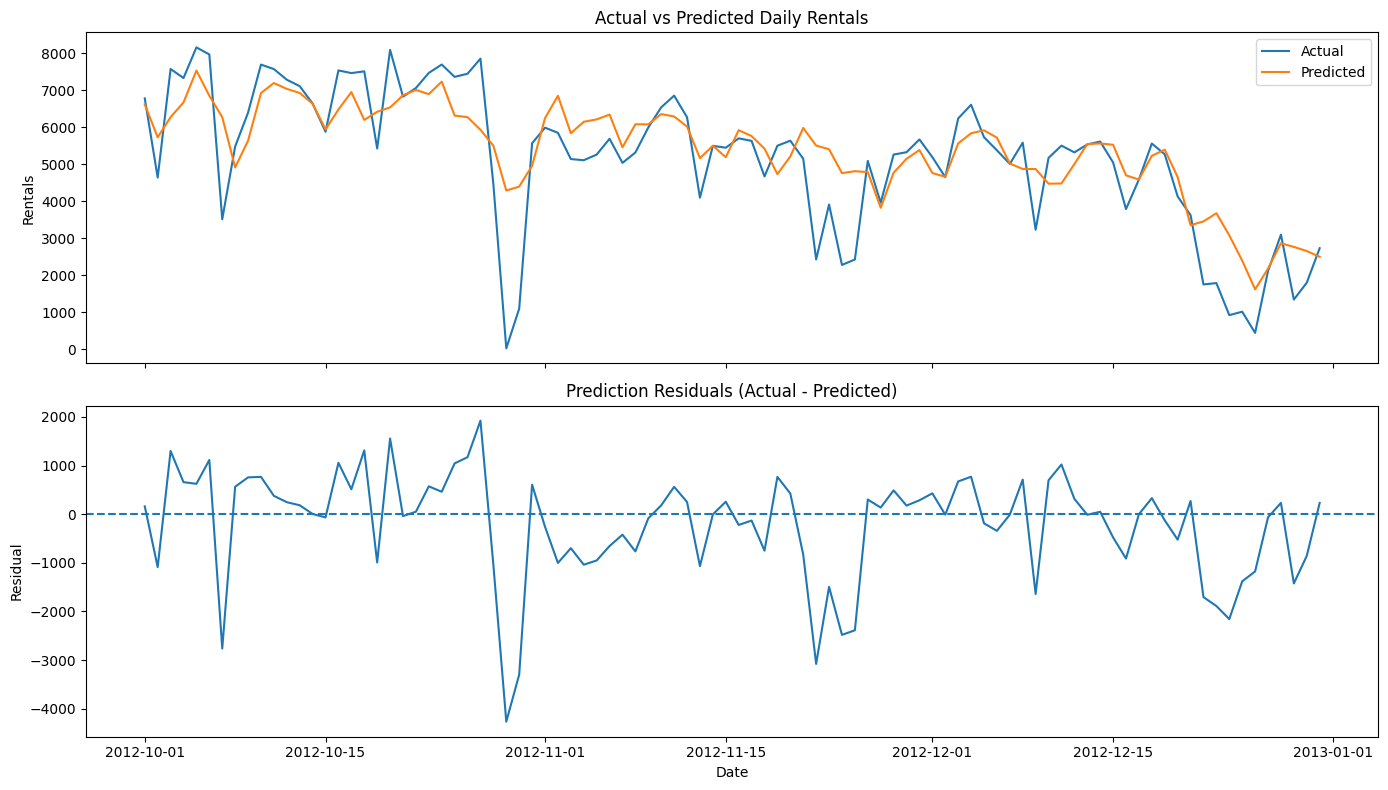

In [42]:
best_model_name = "Linear Regression"

actual = pd.Series(
    y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test,
    index=X_test.index
)

predicted = pd.Series(
    predictions[best_model_name],
    index=X_test.index
)

residuals = actual - predicted

test_dates = model_df.loc[X_test.index, "dteday"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(test_dates, actual, label="Actual")
axes[0].plot(test_dates, predicted, label="Predicted")
axes[0].set_title("Actual vs Predicted Daily Rentals")
axes[0].set_ylabel("Rentals")
axes[0].legend()

axes[1].plot(test_dates, residuals)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Prediction Residuals (Actual - Predicted)")
axes[1].set_ylabel("Residual")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.savefig('../figures/Prediction_Residuclas_(Actual-Predicted).png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

1. **The model captures the broad trend.** From October through December, actual and predicted rentals generally decline. The model captures some of the overall demand pattern.

2. **It struggles with sudden demand changes.** Around October 29, actual rentals fall close to zero while the prediction remains much higher. The model also overpredicts on several days in late November and December.

3. **Residuals show periods of systematic overprediction.** Several consecutive days have negative residuals, particularly around late October and December. This suggests that the model does not adjust quickly enough when actual demand falls below the level suggested by recent observations.

4. **There are also underpredictions.** Not every large error is an overprediction; the residual table identifies at least one substantial positive residual, on October 27.

***Investigate the worst prediction errors***

In [50]:

# Investigate the largest prediction errors

error_df = pd.DataFrame({
    "Date": model_df.loc[X_test.index, "dteday"].to_numpy(),
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(predictions["Linear Regression"])
})

# Calculate residuals and absolute errors
error_df["Residual"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute_Error"] = error_df["Residual"].abs()

# Add relevant weather and calendar information
diagnostic_cols = [
    "weathersit", "temp", "atemp", "hum", "windspeed",
    "holiday", "workingday", "season", "mnth"
]

for col in diagnostic_cols:
    if col in model_df.columns:
        error_df[col] = model_df.loc[X_test.index, col].to_numpy()

# Display the 10 largest errors
worst_errors = (
    error_df.sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(3)
)

display(worst_errors)

# Save the complete error analysis
error_df.to_csv("../reports/Error_dataframe.csv", index=False)


,Date,Actual,Predicted,Residual,Absolute_Error,weathersit,temp,atemp,hum,windspeed,holiday,workingday,season,mnth
28,2012-10-29,22,4287.399,-4265.399,4265.399,3,0.440,0.439,0.880,0.358,0,1,4,10
29,2012-10-30,1096,4394.244,-3298.244,3298.244,2,0.318,0.310,0.825,0.213,0,1,4,10
52,2012-11-22,2425,5502.452,-3077.452,3077.452,1,0.340,0.350,0.580,0.053,1,0,4,11
6,2012-10-07,3510,6270.321,-2760.321,2760.321,2,0.416,0.420,0.708,0.141,0,0,4,10
54,2012-11-24,2277,4757.493,-2480.493,2480.493,1,0.278,0.249,0.405,0.377,0,0,4,11
55,2012-11-25,2424,4809.976,-2385.976,2385.976,1,0.246,0.258,0.468,0.150,0,0,4,11
84,2012-12-24,920,3076.014,-2156.014,2156.014,2,0.231,0.259,0.791,0.077,0,1,1,12
26,2012-10-27,7852,5928.203,1923.797,1923.797,2,0.530,0.515,0.720,0.236,0,0,4,10
83,2012-12-23,1787,3674.110,-1887.110,1887.110,1,0.246,0.259,0.515,0.133,0,0,1,12
82,2012-12-22,1749,3453.314,-1704.314,1704.314,1,0.266,0.236,0.441,0.407,0,0,1,12


In [40]:
# table of actual and predicted values
error_df = pd.DataFrame({
    "Date": model_df.loc[X_test.index, "dteday"].to_numpy(),
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(predictions["Linear Regression"])
})

# Calculate prediction errors
error_df["Residual"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute_Error"] = error_df["Residual"].abs()

# Add weather and calendar details
diagnostic_cols = [
    "weathersit", "temp", "atemp", "hum", "windspeed",
    "holiday", "workingday", "season", "mnth"
]

for col in diagnostic_cols:
    if col in model_df.columns:
        error_df[col] = model_df.loc[X_test.index, col].to_numpy()

# Show the 10 largest errors first
worst_errors = (
    error_df.sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(3)
)

display(worst_errors)

,Date,Actual,Predicted,Residual,Absolute_Error,weathersit,temp,atemp,hum,windspeed,holiday,workingday,season,mnth
28,2012-10-29,22,5770.604,-5748.604,5748.604,3,0.440,0.439,0.880,0.358,0,1,4,10
6,2012-10-07,3510,7738.191,-4228.191,4228.191,2,0.416,0.420,0.708,0.141,0,0,4,10
52,2012-11-22,2425,5609.927,-3184.927,3184.927,1,0.340,0.350,0.580,0.053,1,0,4,11
29,2012-10-30,1096,3910.506,-2814.506,2814.506,2,0.318,0.310,0.825,0.213,0,1,4,10
54,2012-11-24,2277,4981.627,-2704.627,2704.627,1,0.278,0.249,0.405,0.377,0,0,4,11
86,2012-12-26,441,3104.585,-2663.585,2663.585,3,0.243,0.220,0.823,0.317,0,1,1,12
84,2012-12-24,920,3549.996,-2629.996,2629.996,2,0.231,0.259,0.791,0.077,0,1,1,12
82,2012-12-22,1749,4309.753,-2560.753,2560.753,1,0.266,0.236,0.441,0.407,0,0,1,12
27,2012-10-28,4459,6973.122,-2514.122,2514.122,2,0.478,0.468,0.695,0.398,0,0,4,10
89,2012-12-29,1341,3514.384,-2173.384,2173.384,2,0.253,0.242,0.753,0.124,0,0,1,12


The model tends to overpredict on unusually low-demand days, especially in late October and late December.

However, not all ten largest errors are negative. October 27 has a positive residual, meaning the model underpredicted demand on that day.

Most of the largest errors are negative, indicating that the model has difficulty adjusting its predictions when actual demand falls substantially below recent demand levels.

In [44]:
# Inspect recent observed rental counts around the worst-error dates
check_dates = pd.to_datetime([
    "2012-10-07",
    "2012-10-28",
    "2012-10-29",
    "2012-10-30",
    "2012-11-22",
    "2012-11-24",
    "2012-12-24",
    "2012-12-26",
    "2012-12-29"
])

daily_history = model_df.set_index("dteday")["cnt"].sort_index()

history_rows = []

for date in check_dates:
    history_rows.append({
        "Date": date,
        "Actual": daily_history.get(date, np.nan),
        "Previous_Day": daily_history.get(date - pd.Timedelta(days=1), np.nan),
        "Previous_Week": daily_history.get(date - pd.Timedelta(days=7), np.nan),
        "Previous_28_Day_Mean": (
            daily_history.loc[
                date - pd.Timedelta(days=28):
                date - pd.Timedelta(days=1)
            ].mean()
        )
    })

history_check = pd.DataFrame(history_rows)
display(history_check.round(2))

,Date,Actual,Previous_Day,Previous_Week,Previous_28_Day_Mean
0,2012-10-07,3510,7965,6889,7477.43
1,2012-10-28,4459,7852,6824,6949.54
2,2012-10-29,22,4459,7058,6862.75
3,2012-10-30,1096,22,7466,6621.46
4,2012-11-22,2425,5146,5445,5361.75
5,2012-11-24,2277,3910,5629,5059.32
6,2012-12-24,920,1787,4585,4841.46
7,2012-12-26,441,1013,5267,4587.43
8,2012-12-29,1341,3095,1749,4208.82


The key finding is that the model is struggling when actual demand suddenly drops below its recent history.
1. October 29 is an exceptional observation.
The previous day had 4,459 rentals, while October 29 had only 22. A model relying on recent demand and a rolling average could not reasonably anticipate such a large collapse from those features alone.

2. The lag-1 feature contains useful information, but it isn't enough.
On October 30, the previous day's count was 22. This is exactly the type of situation where a lag feature should help the model adjust downward. However, a linear model combines multiple features, so its prediction may still be pulled upward by longer rolling averages and calendar variables.

3. December suggests a broader demand-level mismatch.
Several days have lower demand than their previous-week values and rolling averages suggest. This may reflect seasonal changes, holidays, or other influences—but the table alone cannot establish the cause.

In [45]:
# Inspect the original daily record around the unusual observation
dates_to_check = pd.date_range(
    start="2012-10-25",
    end="2012-11-02",
    freq="D"
)

columns_to_show = [
    col for col in [
        "dteday", "cnt", "casual", "registered",
        "weathersit", "temp", "atemp", "hum",
        "windspeed", "holiday", "workingday", "season", "mnth"
    ]
    if col in day_df.columns
]

original_check = day_df.copy()
original_check["dteday"] = pd.to_datetime(original_check["dteday"])

display(
    original_check.loc[
        original_check["dteday"].isin(dates_to_check),
        columns_to_show
    ].sort_values("dteday")
)

,dteday,cnt,casual,registered,weathersit,temp,atemp,hum,windspeed,holiday,workingday,season,mnth
663,2012-10-25,7359,875,6484,2,0.550000,0.529688,0.800417,0.124375,0,1,4,10
664,2012-10-26,7444,1182,6262,2,0.545833,0.522750,0.807083,0.132467,0,1,4,10
665,2012-10-27,7852,2643,5209,2,0.530000,0.515133,0.720000,0.235692,0,0,4,10
666,2012-10-28,4459,998,3461,2,0.477500,0.467771,0.694583,0.398008,0,0,4,10
667,2012-10-29,22,2,20,3,0.440000,0.439400,0.880000,0.358200,0,1,4,10
668,2012-10-30,1096,87,1009,2,0.318182,0.309909,0.825455,0.213009,0,1,4,10
669,2012-10-31,5566,419,5147,2,0.357500,0.361100,0.666667,0.166667,0,1,4,10
670,2012-11-01,5986,466,5520,2,0.365833,0.369942,0.581667,0.157346,0,1,4,11
671,2012-11-02,5847,618,5229,1,0.355000,0.356042,0.522083,0.266175,0,1,4,11


October 29's unusually low rental count of 22 is present in the original dataset. The surrounding dates also show unusual demand changes.

- **October 29:** Rentals collapsed from 4,459 to 22. The weather category changed to 3, and humidity was high.
- **October 30:** Rentals remained relatively low at 1,096, even though the weather category returned to 2.
- **October 31:** Rentals rebounded to 5,566.

This represents a sharp, short-lived demand shock. Weather may have contributed to the decline, but these observations alone cannot establish causation. We also cannot determine from this table whether the original value is erroneous.

**Investigate Weather Relationship**

In [46]:
weather_summary = (
    day_df.groupby("weathersit")
    .agg(
        Days=("cnt", "size"),
        Mean_Rentals=("cnt", "mean"),
        Median_Rentals=("cnt", "median"),
        Min_Rentals=("cnt", "min"),
        Max_Rentals=("cnt", "max")
    )
    .round(2)
)

display(weather_summary)

,Days,Mean_Rentals,Median_Rentals,Min_Rentals,Max_Rentals
weathersit,,,,,
1,463,4876.79,4844.0,431,8714
2,247,4035.86,4040.0,605,8362
3,21,1803.29,1817.0,22,4639


The average rental count for category 3 is about 63% lower than category 1. Weather therefore appears to be an important predictor in this dataset.
However, category 3 includes a wide range of rental counts, from 22 to 4,639. Weather category alone cannot explain every low-demand day.

In [47]:
weather_3_days = (
    day_df.loc[
        day_df["weathersit"] == 3,
        ["dteday", "cnt", "temp", "atemp", "hum", "windspeed"]
    ]
    .sort_values("cnt")
)

display(weather_3_days)

,dteday,cnt,temp,atemp,hum,windspeed
667,2012-10-29,22,0.440000,0.439400,0.880000,0.358200
725,2012-12-26,441,0.243333,0.220333,0.823333,0.316546
25,2011-01-26,506,0.217500,0.203600,0.862500,0.293850
68,2011-03-10,623,0.389091,0.385668,0.000000,0.261877
301,2011-10-29,627,0.254167,0.227913,0.882500,0.351371
340,2011-12-07,705,0.410000,0.400246,0.970417,0.266175
105,2011-04-16,795,0.430833,0.425492,0.888333,0.340808
477,2012-04-22,1027,0.396667,0.389504,0.835417,0.344546
325,2011-11-22,1607,0.416667,0.421696,0.962500,0.118792
89,2011-03-31,1685,0.268333,0.257575,0.918333,0.217646


October 29, 2012 is exceptionally low, even compared with the other category-3 observations. Its high humidity and weather category are consistent with poor conditions, but they do not establish why rentals fell to 22.<br>
**Decision:** keep the record for now. Don't remove it simply because it creates a large prediction error.

#### Current Fearues:


In [48]:
print("Weather feature included:", "weathersit" in X_train.columns)

if "weathersit" in X_train.columns:
    print("\nWeather values in training data:")
    print(X_train["weathersit"].value_counts().sort_index())

print("\nFeature columns:")
print(X_train.columns.tolist())

Weather feature included: True

Weather values in training data:
weathersit
1    400
2    194
3     17
Name: count, dtype: int64

Feature columns:
['season', 'yr', 'holiday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'day', 'day_of_week', 'quarter', 'is_weekend', 'cnt_lag_1', 'cnt_lag_2', 'cnt_lag_3', 'cnt_lag_7', 'cnt_lag_14', 'cnt_lag_21', 'cnt_lag_28', 'cnt_rolling_mean_7', 'cnt_rolling_std_7', 'cnt_rolling_mean_14', 'cnt_rolling_std_14', 'cnt_rolling_mean_28', 'cnt_rolling_std_28']


In [49]:
print("model_df shape:", model_df.shape)
print("\nAll model_df columns:")
print(model_df.columns.tolist())

print("\nX_train shape:", X_train.shape)
print("\nX_train columns:")
print(X_train.columns.tolist())

model_df shape: (703, 32)

All model_df columns:
['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'year', 'month', 'day', 'day_of_week', 'quarter', 'is_weekend', 'cnt_lag_1', 'cnt_lag_2', 'cnt_lag_3', 'cnt_lag_7', 'cnt_lag_14', 'cnt_lag_21', 'cnt_lag_28', 'cnt_rolling_mean_7', 'cnt_rolling_std_7', 'cnt_rolling_mean_14', 'cnt_rolling_std_14', 'cnt_rolling_mean_28', 'cnt_rolling_std_28']

X_train shape: (611, 28)

X_train columns:
['season', 'yr', 'holiday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'day', 'day_of_week', 'quarter', 'is_weekend', 'cnt_lag_1', 'cnt_lag_2', 'cnt_lag_3', 'cnt_lag_7', 'cnt_lag_14', 'cnt_lag_21', 'cnt_lag_28', 'cnt_rolling_mean_7', 'cnt_rolling_std_7', 'cnt_rolling_mean_14', 'cnt_rolling_std_14', 'cnt_rolling_mean_28', 'cnt_rolling_std_28']


# 5. Baseline Comparison

In [51]:
# Baseline 1: predict using the previous day's actual rentals
baseline_1day = model_df["cnt"].shift(1).loc[y_test.index]

# Baseline 2: predict using the previous week's actual rentals
baseline_7day = model_df["cnt"].shift(7).loc[y_test.index]

# Collect predictions for comparison
baseline_predictions = {
    "Previous-day Naive": baseline_1day,
    "Previous-week Naive": baseline_7day,
    "Linear Regression": pd.Series(
        np.asarray(predictions["Linear Regression"]),
        index=y_test.index
    )
}

# Calculate MAE
baseline_results = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, prediction)
    }
    for name, prediction in baseline_predictions.items()
])

baseline_results = baseline_results.sort_values("MAE")

display(baseline_results.round(2))


,Model,MAE
2,Linear Regression,797.51
0,Previous-day Naive,951.74
1,Previous-week Naive,1457.59


## Conclusion

This project explored daily bike rental demand forecasting using historical rental data.

The analysis included exploratory data analysis, feature engineering, chronological train-test splitting, and comparison of machine learning models.

Linear Regression, Random Forest, and HistGradientBoosting were evaluated alongside simple forecasting baselines.

The final model was selected based on its performance on the held-out test period, with Mean Absolute Error (MAE) used as the primary evaluation metric.

The analysis showed that:
- Historical rental patterns and calendar features provide useful information for forecasting demand.
- Weather conditions are associated with differences in rental demand.
- The model struggles with sudden and unusually large changes in demand.
- Forecasting errors are not uniform across the test period.

### Limitations

- The dataset covers only two years.
- Sudden demand shocks remain difficult to predict.
- The analysis does not establish causal relationships between weather and rental demand.
- Model performance may change across different seasons and future periods.

### Future Improvements

Potential improvements include testing additional forecasting approaches, incorporating external information such as holidays and local events, and evaluating performance using rolling time-series validation.